In [ ]:
import sys
import os

parent_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)
import pybnesian as pbn
import numpy as np
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import pandas as pd
import timeit
from functools import partial
from tqdm.contrib import tenumerate
import seaborn as sns
import pickle
import matplotlib.pyplot as plt

from adapted_MMCIT import MMCIT
from adapted_CGIT import CGIT
from adapted_DGCIT import DGCIT
from adapted_LCIT import Adapted_LCIT
from adapted_MRCIT import MRCIT
from adapted_Pillai import Pillai
from adapted_CIml import Adapted_CIml
from adapted_CCI import CCI
from adapted_aHist import aHist

In [2]:
try:
    os.mkdir('./results/')
except:
    pass

try:
    os.mkdir('./results/timings/')
except:
    pass

In [3]:
def generate_Z(N, Dz, cont_discrete_ratio=0.5, num_categories=5, seed=None):
    rng = np.random.default_rng(seed)
    D_cont = int(Dz * cont_discrete_ratio)
    D_disc = Dz - D_cont

    Z_cont = rng.standard_normal((N, D_cont))

    Z_disc = np.zeros((N, D_disc), dtype=int)
    for d in range(D_disc):
        probs = rng.dirichlet(np.ones(num_categories))
        Z_disc[:, d] = rng.choice(num_categories, size=N, p=probs)

    return Z_cont, Z_disc

def generate_experiment_unconditionally_dependent(N=1000, Dz=6, cont_discrete_ratio=0.5, m=5, seed=None):
    rng = np.random.default_rng(seed)

    # X ~ Uniform{0, ..., m-1}
    X = rng.integers(0, m, size=N)

    # Y ~ Uniform(X, X+2)
    Y = rng.uniform(X, X + 2.0)

    # Z as before (conditionally independent from X, Y)
    Z_cont, Z_disc = generate_Z(N, Dz, cont_discrete_ratio, seed=seed)

    return X, Y, Z_cont, Z_disc


In [4]:
indep_test_dict = {
    'dgcit': DGCIT,
    'cgit': CGIT,
    'mmcit': MMCIT,
    'mrcit': partial(MRCIT, num_f2=20),
    'pillai':Pillai,
    'knncit': partial(
        pbn.MixedKMutualInformation,
        shuffle_neighbors=5,
        samples=100,
        scaling="normalized_rank",
        gamma_approx=True,
        adaptive_k=True
    ),
    'ciml':Adapted_CIml,
    'lcit': partial(Adapted_LCIT, n_components=32, hidden_sizes=[4]),
    'cci':partial(CCI, nperm=100),
    'ahist':aHist,
}

#### Empirical complexity with the sample size

In [ ]:
n_trials = 10
n_datasets = 5


for indep_test_name in indep_test_dict.keys():
    if os.path.isfile(f'./results/timings/{indep_test_name}_at_samples.pkl'):
        continue
    timings = {}
    for _, num_samples in tenumerate(range(200, 2001, 100)):
        timings[num_samples] = []
        for seed, n_dataset in tenumerate(range(n_datasets)):
            X, Y, Z_cont, Z_disc = generate_experiment_unconditionally_dependent(num_samples, 2, 0.5, 5, seed=123*(seed + 1))
            df = pd.DataFrame([X, Y] + Z_cont.T.tolist() + Z_disc.T.tolist()).T
            for i in range(len(df.columns)):
                if i == 0 or i > (len(df.columns) - 2) // 2 + 1:
                    df.iloc[:, i] = df.iloc[:, i].astype(str).astype('category')
            x = str(df.columns[0])
            y = str(df.columns[1])
            z = [str(x) for x in df.columns[2:]]
            categorical_df = df.select_dtypes(include=['category'])
            # Count frequency of each unique configuration
            min_cluster_size = categorical_df.value_counts().min()

            df.columns = [str(col) for col in df.columns]

            if indep_test_name != 'knncit':
                indep_test = indep_test_dict[indep_test_name](df=df)
            else:
                indep_test = indep_test_dict[indep_test_name](df=df, k=len(df)//10)

            time_i_test = timeit.repeat('indep_test.pvalue(x, y, z)', repeat=1, number=n_trials, globals=globals())
                
            timings[num_samples].append((np.mean(time_i_test),))

    with open(f'./results/timings/{indep_test_name}_at_samples.pkl', "wb") as f:
        pickle.dump(timings, f)

In [5]:
cmap = plt.get_cmap('tab10')
color_map = {name: cmap(i) for i, name in enumerate(indep_test_dict.keys())}

In [6]:
norm = [np.log(i) for i in range(200, 2001, 100)]

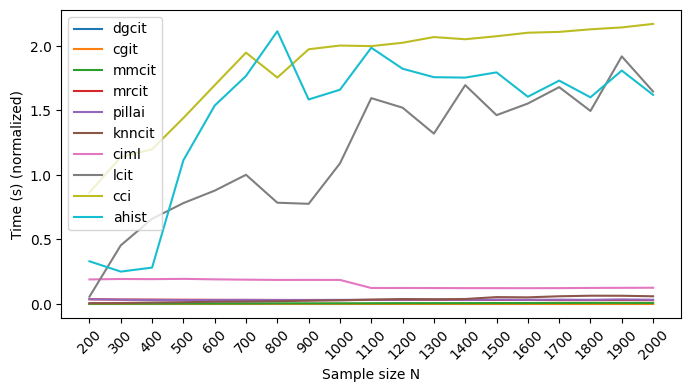

In [7]:
plt.figure(figsize=(8, 4))
n_trials = 10
for indep_test_name in indep_test_dict.keys():
    try:
        with open(f'./results/timings/{indep_test_name}_at_samples.pkl', "rb") as f:
            timings = pickle.load(f)
    except Exception as e:
        continue

    for key in timings.keys():
        timings[key] = np.array(timings[key])/n_trials
    timings = list(timings.values())
    timings = np.array(timings).squeeze(-1)

    sns.lineplot(np.mean(timings, axis=1)/norm, label=indep_test_name)
plt.xticks(ticks= [i for i,_ in enumerate(range(200, 2001, 100))], labels=[i for i in range(200, 2001, 100)], rotation=45)
plt.xlabel("Sample size N")
plt.ylabel("Time (s) (normalized)")



plt.legend() 

In [8]:
n_trials = 10
for indep_test_name in indep_test_dict.keys():
    try:
        with open(f'./results/timings/{indep_test_name}_at_samples.pkl', "rb") as f:
            timings = pickle.load(f)
    except Exception as e:
        continue

    for key in timings.keys():
        timings[key] = np.array(timings[key])/n_trials
    timings = list(timings.values())
    timings = np.array(timings).squeeze(-1) * 1000

    m = np.mean(timings, axis=1)
    
    s = np.array2string(m[::2], formatter={'float_kind': lambda v: f'& {v:.2f}'})

    print('\n', indep_test_name, s)



 dgcit [& 0.03 & 0.03 & 0.03 & 0.03 & 0.03 & 0.03 & 0.03 & 0.03 & 0.03 & 0.03]

 cgit [& 0.70 & 0.72 & 0.73 & 0.72 & 0.76 & 0.75 & 0.76 & 0.78 & 0.79 & 0.80]

 mmcit [& 10.01 & 13.12 & 17.69 & 28.38 & 31.85 & 42.41 & 43.81 & 50.88 & 59.49
 & 56.91]

 mrcit [& 191.35 & 199.66 & 202.21 & 204.31 & 202.73 & 213.93 & 218.98 & 226.40
 & 222.54 & 221.31]

 pillai [& 190.31 & 182.05 & 189.50 & 199.05 & 216.79 & 227.75 & 225.36 & 232.24
 & 236.83 & 244.68]

 knncit [& 31.34 & 64.01 & 107.15 & 142.43 & 194.95 & 267.95 & 275.73 & 374.85
 & 475.59 & 448.79]

 ciml [& 1005.59 & 1150.00 & 1217.39 & 1242.99 & 1284.14 & 876.10 & 885.97
 & 899.08 & 928.60 & 952.56]

 lcit [& 296.76 & 3952.93 & 5618.82 & 5244.38 & 7525.12 & 10786.88 & 12288.66
 & 11462.12 & 11214.62 & 12515.36]

 cci [& 4575.10 & 7185.91 & 10847.71 & 11730.52 & 13837.86 & 14356.81
 & 14866.04 & 15512.16 & 15958.35 & 16502.32]

 ahist [& 1749.85 & 1686.41 & 9837.85 & 14132.51 & 11471.31 & 12928.53 & 12711.29
 & 11852.10 & 12007.10 & 123

#### Empirical complexity with the dimensionality of Z

In [ ]:
n_trials = 10
n_datasets = 5


for indep_test_name in indep_test_dict.keys():
    timings = {}
    if os.path.isfile(f'./results/timings/{indep_test_name}_at_zdim.pkl'):
        with open(f'./results/timings/{indep_test_name}_at_zdim.pkl', "rb") as f:
            timings = pickle.load(f)
        # continue
    for _, z_dims in tenumerate(range(0, 14, 1)):
        timings[z_dims] = []
        for seed, n_dataset in tenumerate(range(n_datasets)):
            X, Y, Z_cont, Z_disc = generate_experiment_unconditionally_dependent(1000, z_dims, 0.5, 5, seed=123*(seed + 1))
            df = pd.DataFrame([X, Y] + Z_cont.T.tolist() + Z_disc.T.tolist()).T
            for i in range(len(df.columns)):
                if i == 0 or i > (len(df.columns) - 2) // 2 + 1:
                    df.iloc[:, i] = df.iloc[:, i].astype(str).astype('category')
            x = str(df.columns[0])
            y = str(df.columns[1])
            z = [str(x) for x in df.columns[2:]]
            categorical_df = df.select_dtypes(include=['category'])

            # Count frequency of each unique configuration
            min_cluster_size = categorical_df.value_counts().min()

            df.columns = [str(col) for col in df.columns]

            
            if indep_test_name != 'knncit':
                indep_test = indep_test_dict[indep_test_name](df=df)
            else:
                indep_test = indep_test_dict[indep_test_name](df=df, k=len(df)//10)

            time_i_test = timeit.repeat('indep_test.pvalue(x, y, z)', repeat=10, number=n_trials, globals=globals())
                        
            timings[z_dims].append((np.mean(time_i_test),))

            with open(f'./results/timings/{indep_test_name}_at_zdim.pkl', "wb") as f:
                pickle.dump(timings, f)

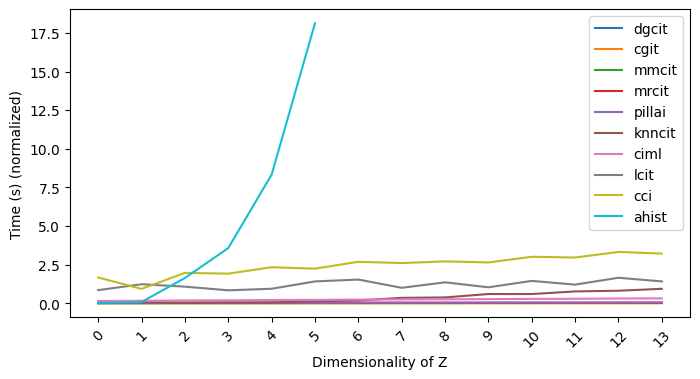

In [10]:
plt.figure(figsize=(8, 4))
n_trials = 10
for indep_test_name in indep_test_dict.keys():
    try:
        with open(f'./results/timings/{indep_test_name}_at_zdim.pkl', "rb") as f:
            timings = pickle.load(f)
    except Exception as e:
        continue

    for key in timings.keys():
        timings[key] = np.array(timings[key])/n_trials
    timings = list(timings.values())

    if indep_test_name == 'ahist':
        timings = timings[:-1]
    timings = np.array(timings).squeeze(-1)

    sns.lineplot(np.mean(timings, axis=1)/np.log(1000), label=indep_test_name)
plt.xticks(ticks= [i for i,_ in enumerate(range(0, 14, 1))], labels=[i for i in range(0, 14, 1)], rotation=45)
plt.xlabel("Dimensionality of Z")
plt.ylabel("Time (s) (normalized)")



plt.legend() 

In [24]:
for indep_test_name in indep_test_dict.keys():
    n_trials = 10
    try:
        with open(f'./results/timings/{indep_test_name}_at_zdim.pkl', "rb") as f:
            timings = pickle.load(f)
    except Exception as e:
        continue

    for key in timings.keys():
        timings[key] = np.array(timings[key])
    timings = list(timings.values())

    if indep_test_name == 'ahist':
        timings = timings[:-1]
        n_trials = np.array([10, 10, 10, 10, 10, 3]).reshape(6, 1, 1)

    timings = np.array(timings)/n_trials
            
    timings = timings.squeeze(-1) * 1000

    # m = np.mean(timings, axis=1)[[0, 1, 2, 3, 5, 7, 9, 11, 12, 13]]
    m = np.mean(timings, axis=1)

    s = np.array2string(m, formatter={'float_kind': lambda v: f'& {v:.2f}'})

    print('\n', indep_test_name, s)


 dgcit [& 0.02 & 0.02 & 0.03 & 0.04 & 0.04 & 0.05 & 0.06 & 0.07 & 0.08 & 0.10
 & 0.11 & 0.14 & 0.15 & 0.19]

 cgit [& 0.69 & 0.73 & 0.76 & 0.73 & 0.79 & 0.86 & 1.00 & 1.13 & 1.21 & 1.42
 & 1.38 & 2.40 & 2.34 & 7.91]

 mmcit [& 14.67 & 24.55 & 31.71 & 46.19 & 55.96 & 70.64 & 70.16 & 92.30 & 95.01
 & 115.74 & 127.70 & 147.35 & 150.83 & 170.87]

 mrcit [& 105.97 & 213.54 & 204.76 & 201.36 & 199.89 & 200.81 & 208.32 & 213.07
 & 211.51 & 219.11 & 216.27 & 220.04 & 220.58 & 220.19]

 pillai [& 95.59 & 93.72 & 211.49 & 220.28 & 256.52 & 249.86 & 287.03 & 294.63
 & 302.11 & 312.49 & 319.81 & 325.72 & 336.92 & 353.33]

 knncit [& 346.20 & 380.48 & 192.47 & 351.39 & 359.74 & 888.52 & 1251.67 & 2434.87
 & 2619.75 & 4139.25 & 4133.38 & 5302.81 & 5605.91 & 6478.21]

 ciml [& 1029.18 & 1106.09 & 1260.56 & 1313.64 & 1459.77 & 1513.82 & 1647.76
 & 1726.40 & 1782.64 & 1850.20 & 1962.80 & 2001.10 & 2137.29 & 2190.14]

 lcit [& 5878.69 & 8514.51 & 7435.44 & 5795.35 & 6494.45 & 9776.28 & 10606.85
 & 6923